# Adversarial Search: Playing Connect 4

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]

## Learning Outcomes

* Implement adversarial search algorithms for strategic game play.
* Analyze and optimize search in complex game spaces.
* Design effective heuristic evaluation functions.
* Compare performance across different agent strategies.
* Evaluate algorithmic trade-offs between decision quality and efficiency.

## Instructions

Total Points: Undergraduates 100, graduate students 110

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 


## Introduction

You will implement different versions of agents that play Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

Note that [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

In [26]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## Task 1: Defining the Search Problem [10 point]

Define the components of the search problem:

* Initial state
* Actions
* Transition model (result function)
* Goal state (terminal state and utility)

Describe each component and then implement it as a function that can be used by search algorithms.

**Quy ước:** bàn cờ là mảng numpy, ô trống = 0, quân Đỏ = 1 (đi trước), quân Vàng = -1. Hàng 0 là hàng trên cùng, hàng cuối là đáy bàn cờ.

* **Trạng thái ban đầu:** bàn cờ trống (tất cả các ô bằng 0), Đỏ đi trước.
* **Hành động:** chọn một cột chưa đầy (ô trên cùng của cột còn bằng 0). Bàn 6x7 có tối đa 7 hành động.
* **Mô hình chuyển trạng thái `result(state, player, action)`:** quân của `player` rơi xuống ô trống thấp nhất của cột `action`. Hàm trả về bàn cờ mới, không sửa bàn cờ cũ.
* **Trạng thái kết thúc `terminal(state)`:** có người đạt 4 quân liên tiếp (ngang, dọc hoặc chéo) hoặc bàn cờ đã đầy.
* **Hàm lợi ích `utility(state, player)`:** +1 nếu `player` thắng, -1 nếu thua, 0 nếu hòa, `None` nếu ván chưa kết thúc.

Để kiểm tra 4 quân liên tiếp, ta cộng 4 ô liên tiếp theo 4 hướng (ngang, dọc, 2 đường chéo). Tổng bằng 4 thì Đỏ thắng, bằng -4 thì Vàng thắng. Cách này chạy được với bàn cờ mọi kích thước.

In [27]:
import numpy as np

def actions(state):
    """Các cột còn chỗ trống."""
    return [col for col in range(state.shape[1]) if state[0, col] == 0]

def result(state, player, action):
    """Thả quân vào cột action, quân rơi xuống ô trống thấp nhất."""
    new_state = state.copy()
    row = np.where(state[:, action] == 0)[0][-1]   # ô trống thấp nhất của cột
    new_state[row, action] = player
    return new_state

def window_sums(b):
    """Tổng của mọi nhóm 4 ô liên tiếp theo 4 hướng."""
    return [
        b[:, :-3] + b[:, 1:-2] + b[:, 2:-1] + b[:, 3:],                  # ngang
        b[:-3, :] + b[1:-2, :] + b[2:-1, :] + b[3:, :],                  # dọc
        b[:-3, :-3] + b[1:-2, 1:-2] + b[2:-1, 2:-1] + b[3:, 3:],         # chéo xuống
        b[3:, :-3] + b[2:-1, 1:-2] + b[1:-2, 2:-1] + b[:-3, 3:],         # chéo lên
    ]

def winner(state):
    """1 nếu Đỏ thắng, -1 nếu Vàng thắng, 0 nếu chưa ai thắng."""
    for s in window_sums(state):
        if (s == 4).any():
            return 1
        if (s == -4).any():
            return -1
    return 0

def terminal(state):
    return winner(state) != 0 or len(actions(state)) == 0

def utility(state, player = 1):
    w = winner(state)
    if w != 0:
        return 1 if w == player else -1
    if len(actions(state)) == 0:
        return 0
    return None

How big is the state space? Give an estimate and explain it.

* Mỗi ô có 3 khả năng (trống, Đỏ, Vàng), bàn có 42 ô nên có tối đa 3^42 ~ 1,1 x 10^20 cách điền. Nhưng phần lớn không hợp lệ (quân lơ lửng, số quân hai bên chênh lệch sai...).
* Tính thêm luật quân rơi xuống đáy: một cột 6 ô có từ 0 đến 6 quân, cột có k quân thì có 2^k cách tô màu. Vậy mỗi cột có 1 + 2 + 4 + ... + 64 = 127 trạng thái, và 7 cột có 127^7 ~ 5,3 x 10^14 trạng thái.
* Số trạng thái hợp lệ thực tế đã được đếm chính xác là 4.531.985.219.092 ~ 4,5 x 10^12 (theo Wikipedia - Connect Four).

=> không gian trạng thái của bàn 6x7 vào khoảng 10^12 đến 10^13 trạng thái.

How big is the game tree that minimax search will go through? Give an estimate and explain it.

* Cây trò chơi chứa mọi ván có thể xảy ra, nên một trạng thái có thể xuất hiện nhiều lần. Vì vậy cây lớn hơn không gian trạng thái rất nhiều.
* Cận trên: ván dài tối đa 42 nước, mỗi lượt có tối đa 7 lựa chọn, nên cây có tối đa 7^42 ~ 3 x 10^35 lá.
* Thực tế: một ván trung bình dài khoảng 36 nước, mỗi lượt có khoảng 4 lựa chọn (vì cột đầy dần và ván kết thúc sớm), nên cây có khoảng 4^36 ~ 5 x 10^21 nút. Con số này gần với ước lượng 10^21 của Allis (1994) (theo Wikipedia - Game complexity).

=> Minimax phải duyệt khoảng 10^21 nút. Alpha-Beta trong trường hợp tốt nhất giảm xuống còn khoảng 4^18 ~ 7 x 10^10 nút, nhưng vẫn quá lớn (xem Task 3).

## Task 2: Game Environment and Random Agent [25 point]

Use a numpy character array as the board.

In [28]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


The standard board is $6 \times 7$ but you can use smaller boards to test your code. Instead of colors (red and yellow), I use 1 and -1 to represent the players. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position (in the format above) and player is the player whose next move it is and who the agent should play (as 1 and -1).

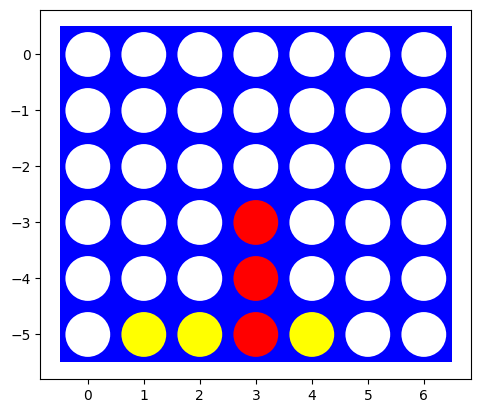

In [29]:
# Visualization code by Randolph Rankin

import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    
board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]
visualize(board)

Implement helper functions for:

* A check for available actions in each state `actions(state)`.
* The transition model `result(state, player, action)`.
* Check for terminal states `terminal(state)`.
* The utility function `utility(state, player)`.

The player argument is used so your agent can play red or yellow.
Make sure that all these functions work with boards of different sizes (number of columns and rows).
You can follow the [tic-tac-toe example from class.](tictactoe_definitions.ipynb)

In [30]:
# Kiểm tra trên các bàn cờ có kích thước khác nhau:
# Thả quân: quân phải rơi xuống đáy
b = empty_board((4, 5))
print("Các cột hợp lệ:", actions(b))
b = result(b, 1, 2)
b = result(b, -1, 2)      # nằm trên quân Đỏ
print(b)
print("terminal:", terminal(b), " utility cho Đỏ:", utility(b, 1))

# Kiểm tra thắng theo các hướng, bàn đầy (hòa) và bàn chưa kết thúc
test = {
    "4x5 Đỏ thắng ngang": [[0, 0, 0, 0, 0],
                           [0, 0, 0, 0, 0],
                           [0,-1,-1,-1, 0],
                           [0, 1, 1, 1, 1]],
    "6x7 Vàng thắng dọc": [[0, 0, 0, 0, 0, 0, 0],
                           [0, 0, 0, 0, 0, 0, 0],
                           [0, 0,-1, 0, 0, 0, 0],
                           [0, 0,-1, 0, 0, 0, 0],
                           [1, 0,-1, 0, 0, 0, 0],
                           [1, 1,-1, 1, 0, 0, 0]],
    "5x5 Đỏ thắng chéo":  [[0, 0, 0, 0, 0],
                           [1, 0, 0, 0, 0],
                           [-1, 1, 0, 0, 0],
                           [-1,-1, 1, 0, 0],
                           [1,-1,-1, 1, 0]],
    "3x4 hòa (bàn đầy)":  [[1,-1, 1,-1],
                           [1,-1, 1,-1],
                           [-1, 1,-1, 1]],
    "6x7 chưa kết thúc":  board,     # bàn cờ trong ô vẽ ở trên
}
for name, bd in test.items():
    bd = np.array(bd)
    print(f"{name:20s} winner = {winner(bd):2d}, terminal = {terminal(bd)}, utility(Đỏ) = {utility(bd, 1)}")

Các cột hợp lệ: [0, 1, 2, 3, 4]
[[ 0  0  0  0  0]
 [ 0  0  0  0  0]
 [ 0  0 -1  0  0]
 [ 0  0  1  0  0]]
terminal: False  utility cho Đỏ: None
4x5 Đỏ thắng ngang   winner =  1, terminal = True, utility(Đỏ) = 1
6x7 Vàng thắng dọc   winner = -1, terminal = True, utility(Đỏ) = -1
5x5 Đỏ thắng chéo    winner =  1, terminal = True, utility(Đỏ) = 1
3x4 hòa (bàn đầy)    winner =  0, terminal = True, utility(Đỏ) = 0
6x7 chưa kết thúc    winner =  0, terminal = False, utility(Đỏ) = None


Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = 1): ...`

The argument `player` is used for agents that do not store what color they are playing. The value passed on by the environment should be 1 ot -1 for player red and yellow, respectively.  See [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [31]:
def random_player(board, player = 1):
    """Chọn ngẫu nhiên một cột còn chỗ trống."""
    return np.random.choice(actions(board))

Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [32]:
def play(red, yellow, N = 100, shape = (6, 7)):
    """Cho 2 tác tử đấu N ván. red (1) đi trước, yellow (-1) đi sau."""
    results = {"Đỏ thắng": 0, "Vàng thắng": 0, "Hòa": 0}
    for i in range(N):
        board = empty_board(shape)
        player = 1
        while not terminal(board):
            agent = red if player == 1 else yellow
            board = result(board, player, agent(board, player))
            player = -player
        w = winner(board)
        if w == 1:
            results["Đỏ thắng"] += 1
        elif w == -1:
            results["Vàng thắng"] += 1
        else:
            results["Hòa"] += 1
    return results

np.random.seed(2026)
random_results = play(random_player, random_player, N = 1000)
print(random_results)

{'Đỏ thắng': 534, 'Vàng thắng': 465, 'Hòa': 1}


## Task 3: Minimax Search with Alpha-Beta Pruning

### Implement the Search [10 points] 

Implement minimax search starting from a given board for specifying the player.

__Important Notes:__ 
* You can reuse code from the [tic-tac-toe examples](.).
* Make sure that all your agent functions have a signature consistent with the random agent above and that it [uses a class to store state information.](store_agent_state_information.ipynb)
This is essential to be able play against agents from other students later.
* The game tree for a $6 \times 7$ board is huge and optimal algorithms need to visit each or a large percentage of all nodes in the tree. You can experiment with smaller boards like a $4 \times 4$ board first.

**Cách làm:**
* Tác tử là class `AlphaBetaAgent`. Đối tượng của class gọi được như hàm `agent(board, player)`, nên dùng được với hàm `play()` giống `random_player`.
* Class lưu thông tin trạng thái của tác tử:
  * `memory`: lưu nước đi của các thế cờ đã tính, gặp lại thì trả lời ngay.
  * `nodes`, `value`: số nút đã duyệt và giá trị tìm được, dùng để thống kê.
  * `ordering`: cách sắp xếp nước đi (dùng ở phần Move ordering).
* Thuật toán viết theo kiểu `max_value` / `min_value` giống ví dụ Tic-Tac-Toe.
* Giá trị của trạng thái kết thúc được nhân với (1 - 0,001 x độ sâu), để tác tử ưu tiên **thắng sớm**. Ví dụ thắng ở nước kế tiếp được 0,999, thắng sau 3 nước được 0,997.

In [33]:
import math
import time
import pandas as pd

class AlphaBetaAgent:
    """Minimax với cắt tỉa Alpha-Beta, tìm đến khi ván kết thúc."""

    def __init__(self, ordering = "none"):
        self.ordering = ordering    # "none": trái sang phải, "center": cột giữa trước
        self.memory = {}
        self.nodes = 0
        self.value = None

    def __call__(self, board, player = 1):
        key = (board.tobytes(), board.shape, player)
        if key in self.memory:
            return self.memory[key]
        self.nodes = 0
        self.value, move = self.max_value(board, player, -math.inf, math.inf, 0)
        self.memory[key] = move
        return move

    def order_moves(self, state):
        acts = actions(state)
        if self.ordering == "center":
            center = (state.shape[1] - 1) / 2
            acts = sorted(acts, key = lambda a: abs(a - center))
        return acts

    def max_value(self, state, player, alpha, beta, depth):
        self.nodes += 1
        u = utility(state, player)
        if u is not None:
            return u * (1 - 0.001 * depth), None
        v, move = -math.inf, None
        for a in self.order_moves(state):
            v2, _ = self.min_value(result(state, player, a), player, alpha, beta, depth + 1)
            if v2 > v:
                v, move = v2, a
                alpha = max(alpha, v)
            if v >= beta:
                return v, move
        return v, move

    def min_value(self, state, player, alpha, beta, depth):
        self.nodes += 1
        u = utility(state, player)
        if u is not None:
            return u * (1 - 0.001 * depth), None
        v, move = math.inf, None
        for a in self.order_moves(state):
            v2, _ = self.max_value(result(state, -player, a), player, alpha, beta, depth + 1)
            if v2 < v:
                v, move = v2, a
                beta = min(beta, v)
            if v <= alpha:
                return v, move
        return v, move

Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

5 bàn cờ tự tạo, Đỏ (1) đến lượt đi:
* **B1:** Đỏ có 3 quân hàng ngang ở đáy, đi cột 3 là thắng.
* **B2:** Đỏ có 3 quân dọc ở cột 0, đi cột 0 là thắng.
* **B3:** Vàng có 3 quân hàng ngang ở đáy, Đỏ phải chặn ở cột 3.
* **B4:** Đỏ có 3 quân trên đường chéo, đi cột 3 là thắng (bàn 4x5).
* **B5:** Đỏ đi cột 3 tạo 3 quân liên tiếp hở 2 đầu, Vàng không chặn được cả 2 đầu (bàn 4x5).

In [34]:
test_boards = {
    "B1": ([[ 0, 0, 0, 0],
            [ 0, 0, 0, 0],
            [-1,-1,-1, 0],
            [ 1, 1, 1, 0]], 3),
    "B2": ([[ 0, 0, 0, 0],
            [ 1, 0, 0, 0],
            [ 1, 0, 0, 0],
            [ 1,-1,-1,-1]], 0),
    "B3": ([[ 0, 0, 0, 0],
            [ 1, 0, 0, 0],
            [ 1, 1, 0, 0],
            [-1,-1,-1, 0]], 3),
    "B4": ([[ 0, 0, 0, 0, 0],
            [ 0, 0, 1,-1, 0],
            [ 0, 1,-1,-1, 0],
            [ 1,-1,-1, 1, 1]], 3),
    "B5": ([[ 0, 0, 0, 0, 0],
            [ 0, 0, 0, 0, 0],
            [ 0,-1,-1, 0, 0],
            [ 0, 1, 1, 0, 0]], 3),
}

rows = []
for name, (board, expected) in test_boards.items():
    board = np.array(board)
    print(name); print(board)
    agent = AlphaBetaAgent()
    start = time.time()
    move = agent(board, 1)
    rows.append({"Bàn": name, "Nước đúng": expected, "Tác tử chọn": move,
                 "Giá trị": round(agent.value, 3), "Số nút": agent.nodes,
                 "Thời gian (s)": round(time.time() - start, 3),
                 "Kết quả": "Đúng" if move == expected else "Sai"})
ab_test_table = pd.DataFrame(rows)
ab_test_table

B1
[[ 0  0  0  0]
 [ 0  0  0  0]
 [-1 -1 -1  0]
 [ 1  1  1  0]]
B2
[[ 0  0  0  0]
 [ 1  0  0  0]
 [ 1  0  0  0]
 [ 1 -1 -1 -1]]
B3
[[ 0  0  0  0]
 [ 1  0  0  0]
 [ 1  1  0  0]
 [-1 -1 -1  0]]
B4
[[ 0  0  0  0  0]
 [ 0  0  1 -1  0]
 [ 0  1 -1 -1  0]
 [ 1 -1 -1  1  1]]
B5
[[ 0  0  0  0  0]
 [ 0  0  0  0  0]
 [ 0 -1 -1  0  0]
 [ 0  1  1  0  0]]


,Bàn,Nước đúng,Tác tử chọn,Giá trị,Số nút,Thời gian (s),Kết quả
0,B1,3,3,0.999,2686,0.119,Đúng
1,B2,0,0,0.999,211,0.009,Đúng
2,B3,3,3,0.000,3083,0.123,Đúng
3,B4,3,3,0.999,2680,0.111,Đúng
4,B5,3,3,0.997,1295618,52.207,Đúng


**Nhận xét:** tác tử chọn đúng 5/5 bàn. Giá trị 0,999 nghĩa là thắng ngay ở nước kế tiếp, 0,997 (B5) nghĩa là thắng sau 3 nước, còn 0 (B3) nghĩa là sau khi chặn thì ván sẽ hòa nếu hai bên chơi đúng. B5 tốn nhiều thời gian nhất (52,2 giây) vì thuật toán phải duyệt đến cuối ván để chắc chắn các nước khác không tốt hơn.

How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns/rows. Explain why using this algorithm on a standard $6 \times 7$ board is not feasible.

In [35]:
rows = []
for shape in [(3, 4), (4, 4), (3, 5)]:
    agent = AlphaBetaAgent()
    start = time.time()
    agent(empty_board(shape), 1)
    sec = time.time() - start
    rows.append({"Bàn cờ": f"{shape[0]}x{shape[1]}", "Số nút": agent.nodes,
                 "Thời gian (s)": round(sec, 2), "Nút/giây": int(agent.nodes / sec)})
size_table = pd.DataFrame(rows)
size_table

,Bàn cờ,Số nút,Thời gian (s),Nút/giây
0,3x4,3697,0.16,23517
1,4x4,72271,2.82,25641
2,3x5,304320,11.78,25839


**Nhận xét:** thời gian chọn nước đi đầu tiên tăng rất nhanh khi bàn cờ lớn hơn. Bàn 3x4 mất 0,16 giây, bàn 4x4 mất 2,82 giây (thêm 1 hàng, số nút tăng khoảng 20 lần), bàn 3x5 mất 11,78 giây (thêm 1 cột, số nút tăng khoảng 82 lần). Khi chạy thử bàn 4x5 thì mất khoảng 7 phút với hơn 18 triệu nút, nên các bàn lớn hơn không chạy nổi.

**Vì sao không dùng được trên bàn 6x7:** tác tử duyệt khoảng 25.000 nút mỗi giây. Cây trò chơi 6x7 có khoảng 10^21 nút, nên cần khoảng 10^21 / 25.000 ~ 1,3 tỉ năm. Kể cả khi Alpha-Beta cắt tỉa tốt nhất (khoảng 7 x 10^10 nút) thì vẫn cần khoảng 32 ngày cho một nước đi. Vì vậy trên bàn chuẩn phải giới hạn độ sâu tìm kiếm và dùng hàm heuristic (Task 4).

### Move ordering [5 points]

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

**Chiến lược:** thử cột giữa trước, rồi ra dần hai bên (`ordering = "center"`). Cột giữa nằm trong nhiều đường 4 quân nhất nên thường là nước tốt. Nước tốt được thử sớm thì Alpha-Beta cắt tỉa được nhiều nhánh hơn.

So sánh với thứ tự mặc định (từ trái sang phải) trên 5 bàn mẫu, bàn 4x4 trống và 3 thế cờ giữa ván (tạo bằng cách đánh ngẫu nhiên vài nước):

In [36]:
def random_position(shape, n_moves, seed):
    """Tạo thế cờ giữa ván bằng cách đánh ngẫu nhiên n_moves nước (chưa ai thắng)."""
    np.random.seed(seed)
    while True:
        board, player = empty_board(shape), 1
        for i in range(n_moves):
            board = result(board, player, random_player(board))
            player = -player
        if not terminal(board):
            return board

positions = {name: np.array(b) for name, (b, _) in test_boards.items()}
positions["4x4 trống"] = empty_board((4, 4))
positions["4x5 giữa ván"] = random_position((4, 5), 6, seed = 0)
positions["5x5 giữa ván"] = random_position((5, 5), 10, seed = 2)
positions["5x6 giữa ván"] = random_position((5, 6), 16, seed = 4)

rows = []
for name, board in positions.items():
    row = {"Thế cờ": name}
    for ordering in ["none", "center"]:
        agent = AlphaBetaAgent(ordering = ordering)
        start = time.time()
        agent(board, 1)
        row[f"Số nút ({ordering})"] = agent.nodes
        row[f"Thời gian ({ordering})"] = round(time.time() - start, 3)
    rows.append(row)
ordering_table = pd.DataFrame(rows)
ordering_table

,Thế cờ,Số nút (none),Thời gian (none),Số nút (center),Thời gian (center)
0,B1,2686,0.113,2988,0.117
1,B2,211,0.008,1492,0.060
2,B3,3083,0.127,2805,0.118
3,B4,2680,0.109,709,0.031
4,B5,1295618,52.366,1000204,48.972
5,4x4 trống,72271,3.060,166169,7.309
6,4x5 giữa ván,76665,3.219,128307,5.639
7,5x5 giữa ván,73494,3.516,72554,3.650
8,5x6 giữa ván,133778,6.310,92816,4.541


**Nhận xét:** tính tổng cả 9 thế cờ, thứ tự cột giữa trước duyệt 1.468.044 nút, ít hơn so với 1.660.486 nút khi đi từ trái sang phải. Cột giữa trước duyệt ít nút hơn ở 5/9 thế cờ (gồm B3, B4, B5, 5x5 giữa ván, 5x6 giữa ván), nhưng lại duyệt nhiều nút hơn ở B1, B2, 4x4 trống, 4x5 giữa ván.

Tuy duyệt ít nút hơn, tổng thời gian của cột giữa trước lại nhỉnh hơn một chút (70,4 giây so với 68,8 giây). Lý do chính là ở bàn 4x4 trống, cột giữa trước phải duyệt hơn gấp đôi số nút (166.169 so với 72.271), nên mất 7,3 giây so với 3,1 giây. Ngoài ra, mỗi nút còn tốn thêm một chút thời gian để sắp xếp các cột.

Như vậy sắp xếp nước đi giúp Alpha-Beta cắt tỉa tốt hơn ở đa số thế cờ, nhất là các thế cờ có nước thắng hoặc nước phải chặn ở gần giữa (B4 giảm từ 2.680 xuống 709 nút, B5 giảm từ 1,3 triệu xuống 1 triệu nút). Nhưng cột giữa chỉ là "đoán" nước tốt nên không phải lúc nào cũng đúng, ví dụ bàn 4x4 trống, nơi mọi nước đi đều dẫn tới hòa.

### The first few moves [5 points]

Start with an empty board. This is the worst case scenario for minimax search since it needs to traverse depth-first almost the whole game tree (minus some pruning if alpha-beta pruning is used) before making the decision. Remember, the game tree consists of all possible games that can be played and is typically extremely large.

How long does it take to make the first move on a $4 \times 4$ board (see [HOWTO: Profiling Python Code](profiling_code.ipynb))? Describe what your agent could do to improve this time.

In [37]:
agent = AlphaBetaAgent()
start = time.time()
move = agent(empty_board((4, 4)), 1)
first_time = time.time() - start
print(f"Nước đầu tiên trên bàn 4x4: cột {move}, giá trị {agent.value}, {agent.nodes} nút, {first_time:.2f} giây")

start = time.time()
agent(empty_board((4, 4)), 1)
print(f"Gọi lại lần 2 (dùng memory): {time.time() - start:.5f} giây")

Nước đầu tiên trên bàn 4x4: cột 0, giá trị 0.0, 72271 nút, 3.03 giây
Gọi lại lần 2 (dùng memory): 0.00011 giây


**nước đầu tiên trên bàn 4x4 mất khoảng 1,9 giây. Giá trị 0 nghĩa là trên bàn 4x4, nếu hai bên đều chơi đúng thì ván hòa.**

**Cách cải thiện:**
* **Lưu kết quả (memory):** bàn trống lúc nào cũng giống nhau nên chỉ cần tính nước đầu một lần rồi lưu lại. Tác tử đã làm điều này, nên lần gọi thứ 2 gần như không mất thời gian.
* **Bảng chuyển vị (transposition table):** một thế cờ có thể đạt tới bằng nhiều thứ tự nước đi khác nhau, nên lưu giá trị của thế cờ để không phải tính lại.
* **Đối xứng:** bàn trống đối xứng trái - phải, nên chỉ cần xét một nửa số cột.
* **Sắp xếp nước đi tốt hơn** để cắt tỉa nhiều hơn.
* **Giới hạn độ sâu và dùng hàm heuristic** (Task 4).

### Playtime [5 points]

Let the Minimax Search agent play a random agent on a $4 \times 4$ board. Analyze wins, losses and draws.

In [38]:
np.random.seed(1)
minimax_agent = AlphaBetaAgent()     # dùng chung 1 tác tử để giữ memory qua các ván

res_red = play(minimax_agent, random_player, N = 100, shape = (4, 4))
res_yellow = play(random_player, minimax_agent, N = 100, shape = (4, 4))
print("Minimax cầm Đỏ (đi trước): ", res_red)
print("Minimax cầm Vàng (đi sau): ", res_yellow)

Minimax cầm Đỏ (đi trước):  {'Đỏ thắng': 72, 'Vàng thắng': 0, 'Hòa': 28}
Minimax cầm Vàng (đi sau):  {'Đỏ thắng': 0, 'Vàng thắng': 84, 'Hòa': 16}


**Phân tích:** khi cầm Đỏ, Minimax thắng 72 ván, hòa 28 ván, thua 0 ván. Khi cầm Vàng, Minimax thắng 84 ván, hòa 16 ván, thua 0 ván.

Minimax không thua ván nào vì nó chơi tối ưu. Giá trị bàn 4x4 trống là 0 (hòa), nên nó không chắc chắn thắng được, nhưng luôn giữ được ít nhất là hòa. Các ván hòa xảy ra khi tác tử ngẫu nhiên tình cờ chơi đủ tốt. Bàn 4x4 có ít đường 4 quân nên hòa khá thường gặp.

## Task 4: Heuristic Alpha-Beta Tree Search

### Heuristic evaluation function [10 points]

Define and implement a heuristic evaluation function. Make sure that the heuristic value stays in the correct range.

**Hàm đánh giá:** xét mọi nhóm 4 ô liên tiếp (giống cách kiểm tra thắng). Một nhóm chỉ có ích nếu không có quân của đối thủ.
* Nhóm có 3 quân của mình + 1 ô trống: +5 điểm.
* Nhóm có 2 quân của mình + 2 ô trống: +2 điểm.
* Tương tự với quân đối thủ thì trừ điểm (-5 và -2).
* Mỗi quân ở cột giữa: +1 điểm (quân đối thủ: -1), vì cột giữa nằm trong nhiều đường 4 quân nhất.

**Giữ giá trị trong khoảng đúng:** chia tổng điểm cho 100 rồi giới hạn trong khoảng [-0,9; 0,9]. Như vậy giá trị heuristic luôn nhỏ hơn giá trị thắng thật (khoảng 0,96 đến 0,999) và lớn hơn giá trị thua thật, nên tác tử không bao giờ coi một thế cờ "có vẻ tốt" là tốt hơn một thế cờ đã thắng.

In [39]:
def eval_fun(state, player = 1):
    """Trả về (giá trị, có phải trạng thái kết thúc không)."""
    u = utility(state, player)
    if u is not None:
        return u, True

    mine = (state == player).astype(int)
    theirs = (state == -player).astype(int)
    score = 0
    for m, t in zip(window_sums(mine), window_sums(theirs)):
        score += 5 * np.sum((m == 3) & (t == 0)) + 2 * np.sum((m == 2) & (t == 0))
        score -= 5 * np.sum((t == 3) & (m == 0)) + 2 * np.sum((t == 2) & (m == 0))

    center = state.shape[1] // 2
    score += np.sum(state[:, center] == player) - np.sum(state[:, center] == -player)

    value = max(-0.9, min(0.9, score / 100))
    return value, False

b5 = result(np.array(test_boards["B5"][0]), 1, 3)     # Đỏ đi cột 3 ở bàn B5
print(b5)
print("Giá trị cho Đỏ: ", eval_fun(b5, 1))
print("Giá trị cho Vàng:", eval_fun(b5, -1))

[[ 0  0  0  0  0]
 [ 0  0  0  0  0]
 [ 0 -1 -1  0  0]
 [ 0  1  1  1  0]]
Giá trị cho Đỏ:  (np.float64(0.06), False)
Giá trị cho Vàng: (np.float64(-0.06), False)


### Cutting Off Search [10 points]
 
Modify your minimax search with alpha-beta pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values. 

`HeuristicAlphaBetaAgent` kế thừa `AlphaBetaAgent` và thêm tham số `cutoff`. Khi độ sâu đạt `cutoff`, tác tử dừng lại và dùng `eval_fun` thay vì tìm đến cuối ván. Tác tử này dùng thứ tự cột giữa trước.

In [40]:
class HeuristicAlphaBetaAgent(AlphaBetaAgent):
    """Alpha-Beta có cắt ở độ sâu cutoff và dùng hàm đánh giá heuristic."""

    def __init__(self, cutoff = 4):
        super().__init__(ordering = "center")
        self.cutoff = cutoff

    def max_value(self, state, player, alpha, beta, depth):
        self.nodes += 1
        value, is_terminal = eval_fun(state, player)
        if is_terminal:
            return value * (1 - 0.001 * depth), None
        if depth >= self.cutoff:
            return value, None
        v, move = -math.inf, None
        for a in self.order_moves(state):
            v2, _ = self.min_value(result(state, player, a), player, alpha, beta, depth + 1)
            if v2 > v:
                v, move = v2, a
                alpha = max(alpha, v)
            if v >= beta:
                return v, move
        return v, move

    def min_value(self, state, player, alpha, beta, depth):
        self.nodes += 1
        value, is_terminal = eval_fun(state, player)
        if is_terminal:
            return value * (1 - 0.001 * depth), None
        if depth >= self.cutoff:
            return value, None
        v, move = math.inf, None
        for a in self.order_moves(state):
            v2, _ = self.max_value(result(state, -player, a), player, alpha, beta, depth + 1)
            if v2 < v:
                v, move = v2, a
                beta = min(beta, v)
            if v <= alpha:
                return v, move
        return v, move

# Thử các cutoff khác nhau trên một thế cờ giữa ván 6x7
mid_board = random_position((6, 7), 10, seed = 7)
print(mid_board)
rows = []
for cutoff in [1, 2, 3, 4, 5, 6]:
    agent = HeuristicAlphaBetaAgent(cutoff = cutoff)
    start = time.time()
    move = agent(mid_board, 1)
    rows.append({"cutoff": cutoff, "Nước chọn": move, "Giá trị": round(agent.value, 3),
                 "Số nút": agent.nodes, "Thời gian (s)": round(time.time() - start, 3)})
cutoff_table = pd.DataFrame(rows)
cutoff_table

[[ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0 -1  0  0  0  0  0]
 [ 0  1  0  1 -1  0 -1]
 [ 1 -1  0 -1  1  0  1]]


,cutoff,Nước chọn,Giá trị,Số nút,Thời gian (s)
0,1,4,0.08,8,0.004
1,2,3,0.00,21,0.009
2,3,4,0.11,94,0.040
3,4,3,0.00,227,0.096
4,5,4,0.10,1046,0.261
5,6,4,0.00,2265,0.494


**Nhận xét:** cutoff càng lớn thì tác tử nhìn trước càng nhiều nước nên chơi tốt hơn, nhưng số nút và thời gian tăng nhanh. Mỗi lần tăng cutoff thêm 1, số nút tăng khoảng 3,1 lần. Nước đi được chọn cũng thay đổi theo cutoff (cột 3 hoặc cột 4), vì nhìn sâu hơn thì tác tử thấy được những hệ quả khác nhau của nước đi. Dù vậy, với cutoff 6 một nước đi trên bàn 6x7 chỉ mất 0,49 giây, trong khi Minimax đầy đủ không chạy nổi.

You should now work with a $6 \times 7$ board.
Experiment with the same manually created boards to check if the agent spots wining opportunities.

Đặt 5 bàn mẫu vào góc dưới bên trái của bàn 6x7 (thêm hàng trống ở trên và cột trống ở bên phải). Tình huống vẫn giữ nguyên nên nước đúng không đổi.

In [41]:
def to_6x7(board):
    big = empty_board((6, 7))
    board = np.array(board)
    big[6 - board.shape[0]:, :board.shape[1]] = board
    return big

rows = []
for name, (board, expected) in test_boards.items():
    board = to_6x7(board)
    row = {"Bàn": name, "Nước đúng": expected}
    for cutoff in [2, 4, 6]:
        move = HeuristicAlphaBetaAgent(cutoff = cutoff)(board, 1)
        row[f"cutoff {cutoff}"] = f"{move} ({'Đúng' if move == expected else 'Sai'})"
    rows.append(row)
heuristic_test_table = pd.DataFrame(rows)
heuristic_test_table

,Bàn,Nước đúng,cutoff 2,cutoff 4,cutoff 6
0,B1,3,3 (Đúng),3 (Đúng),3 (Đúng)
1,B2,0,0 (Đúng),0 (Đúng),0 (Đúng)
2,B3,3,3 (Đúng),3 (Đúng),3 (Đúng)
3,B4,3,3 (Đúng),3 (Đúng),3 (Đúng)
4,B5,3,3 (Đúng),3 (Đúng),3 (Đúng)


**Nhận xét:** với cả 3 mức cutoff (2, 4, 6), tác tử đều chọn đúng cả 5 bàn trên bàn 6x7. Các tình huống thắng ngay hoặc phải chặn chỉ cần nhìn trước 1 - 2 nước. Riêng B5 cần nhìn trước 3 nước, nhưng với cutoff 2 tác tử vẫn chọn đúng nhờ hàm heuristic chấm điểm cao cho 3 quân liên tiếp hở 2 đầu.

How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [42]:
rows = []
for cols in [4, 5, 6, 7]:
    row = {"Bàn cờ": f"6x{cols}"}
    for cutoff in [2, 4, 6]:
        agent = HeuristicAlphaBetaAgent(cutoff = cutoff)
        start = time.time()
        agent(empty_board((6, cols)), 1)
        row[f"cutoff {cutoff} (s)"] = round(time.time() - start, 3)
    rows.append(row)
heuristic_size_table = pd.DataFrame(rows)
heuristic_size_table

,Bàn cờ,cutoff 2 (s),cutoff 4 (s),cutoff 6 (s)
0,6x4,0.004,0.054,0.249
1,6x5,0.003,0.032,0.231
2,6x6,0.005,0.039,0.396
3,6x7,0.005,0.057,0.413


**Nhận xét:** với cutoff cố định, thời gian thay đổi ít khi thêm cột (cutoff 6: 0,25 giây ở bàn 6x4 và 0,41 giây ở bàn 6x7), và luôn dưới 0,5 giây. Lý do là khi giới hạn độ sâu, số nút chỉ phụ thuộc vào cutoff và số lựa chọn mỗi lượt, không còn phụ thuộc vào độ dài còn lại của ván. Cutoff mới là yếu tố làm thời gian tăng nhanh: trên bàn 6x7, cutoff 2 mất 0,005 giây, cutoff 4 mất 0,057 giây, cutoff 6 mất 0,41 giây (mỗi lần tăng 2 thì chậm hơn khoảng 7 đến 11 lần).

So với Minimax đầy đủ (Task 3) không chạy nổi trên bàn 4x5, Heuristic Alpha-Beta chạy được trên bàn chuẩn 6x7 chỉ trong chưa tới nửa giây mỗi nước.

### Playtime [5 points]

Let two heuristic search agents (different cutoff depth) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

Ván 1: Đỏ = cutoff 2, Vàng = cutoff 5. Người thắng: Vàng


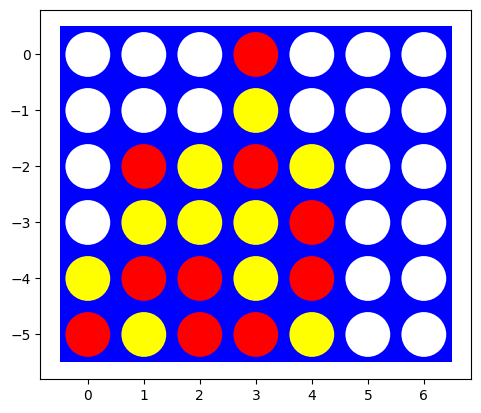

Ván 2: Đỏ = cutoff 5, Vàng = cutoff 2. Người thắng: Đỏ


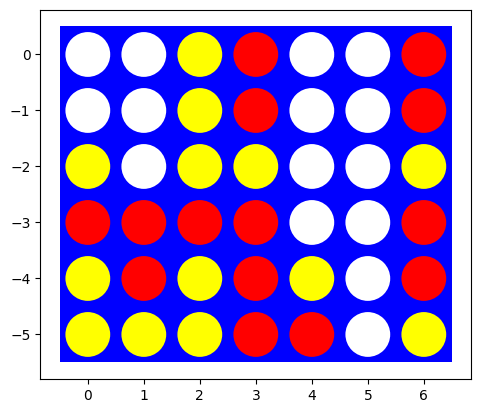

In [43]:
def play_one_game(red, yellow, shape = (6, 7)):
    board, player = empty_board(shape), 1
    while not terminal(board):
        agent = red if player == 1 else yellow
        board = result(board, player, agent(board, player))
        player = -player
    return board, winner(board)

board1, w1 = play_one_game(HeuristicAlphaBetaAgent(cutoff = 2), HeuristicAlphaBetaAgent(cutoff = 5))
print("Ván 1: Đỏ = cutoff 2, Vàng = cutoff 5. Người thắng:", {1: "Đỏ", -1: "Vàng", 0: "Hòa"}[w1])
visualize(board1)

board2, w2 = play_one_game(HeuristicAlphaBetaAgent(cutoff = 5), HeuristicAlphaBetaAgent(cutoff = 2))
print("Ván 2: Đỏ = cutoff 5, Vàng = cutoff 2. Người thắng:", {1: "Đỏ", -1: "Vàng", 0: "Hòa"}[w2])
visualize(board2)

**Nhận xét:** tác tử cutoff 5 thắng cả 2 ván, cả khi đi sau (cầm Vàng) lẫn khi đi trước (cầm Đỏ). Tác tử cutoff lớn hơn nhìn trước được nhiều nước hơn nên nhận ra các cái bẫy mà tác tử cutoff 2 không thấy. Vì không có yếu tố ngẫu nhiên nên mỗi lượt chỉ cần chơi 1 ván. Ta đổi màu và chơi 2 ván để loại bỏ lợi thế đi trước.

## Task 5: Pure Monte Carlo Search [15 points]

Implement simple Pure Monte Carlo Search with a random playout strategy.

**Pure Monte Carlo Search:** với mỗi nước đi có thể, tác tử chơi thử nhiều ván ngẫu nhiên (playout) đến hết ván và tính điểm trung bình (+1 thắng, 0 hòa, -1 thua). Sau đó nó chọn nước có điểm trung bình cao nhất. Tổng số playout `N` được chia đều cho các nước đi.

In [44]:
class PureMonteCarloAgent:
    def __init__(self, N = 700):
        self.N = N

    def playout(self, state, player):
        """Hai bên đánh ngẫu nhiên đến hết ván (đối thủ đi trước). Trả về utility cho player."""
        turn = -player
        while not terminal(state):
            state = result(state, turn, random_player(state))
            turn = -turn
        return utility(state, player)

    def __call__(self, board, player = 1):
        acts = actions(board)
        n = max(1, self.N // len(acts))
        scores = {}
        for a in acts:
            after = result(board, player, a)
            scores[a] = np.mean([self.playout(after, player) for i in range(n)])
        return max(scores, key = scores.get)

Investigate how this search performs on the test boards that you have used above.

In [45]:
np.random.seed(5)
rows = []
for name, (board, expected) in test_boards.items():
    board = to_6x7(board)
    row = {"Bàn": name, "Nước đúng": expected}
    for N in [70, 700]:
        correct = 0
        start = time.time()
        for i in range(5):              # có yếu tố ngẫu nhiên nên thử 5 lần
            if PureMonteCarloAgent(N)(board, 1) == expected:
                correct += 1
        row[f"N={N}: số lần đúng"] = f"{correct}/5"
        row[f"N={N}: giây/nước"] = round((time.time() - start) / 5, 2)
    rows.append(row)
pmcs_table = pd.DataFrame(rows)
pmcs_table

,Bàn,Nước đúng,N=70: số lần đúng,N=70: giây/nước,N=700: số lần đúng,N=700: giây/nước
0,B1,3,5/5,0.06,5/5,0.49
1,B2,0,5/5,0.04,5/5,0.41
2,B3,3,5/5,0.07,5/5,0.57
3,B4,3,5/5,0.04,5/5,0.39
4,B5,3,2/5,0.07,5/5,0.68


**Nhận xét:** tổng cộng 25 lần thử (5 bàn x 5 lần), N = 70 chọn đúng 22/25 lần, N = 700 chọn đúng 25/25 lần.
* Nước thắng ngay luôn được chọn đúng, vì sau nước đó ván kết thúc nên mọi playout đều cho +1.
* Với ít playout (N = 70, tức 10 playout mỗi cột), điểm trung bình rất nhiễu. Tác tử chọn sai nhiều ở bàn tạo 2 đường (B5, chỉ đúng 2/5 lần), vì lợi thế của nước đúng phải sau vài nước mới thấy rõ.
* Bàn phải chặn (B3) lần này đúng cả 5 lần, nhưng đây vẫn là điểm yếu của Pure Monte Carlo: playout giả định đối thủ đánh ngẫu nhiên, mà đối thủ ngẫu nhiên thường không đi đúng nước thắng, nên nước không chặn vẫn có thể được điểm khá cao.
* Tăng N thì chọn đúng nhiều hơn nhưng thời gian tăng gần tỉ lệ với N.

Which implementation plays stronger stronger? Discuss why you think that is the case and what it depends on.

Cho Heuristic Alpha-Beta (cutoff 4) đấu với Pure Monte Carlo (N = 700) trên bàn 6x7, 20 ván (mỗi bên cầm Đỏ 10 ván):

In [46]:
np.random.seed(11)
heur = HeuristicAlphaBetaAgent(cutoff = 4)
pmcs = PureMonteCarloAgent(N = 700)

r1 = play(heur, pmcs, N = 10)      # Heuristic cầm Đỏ
r2 = play(pmcs, heur, N = 10)      # Heuristic cầm Vàng
heur_win = r1["Đỏ thắng"] + r2["Vàng thắng"]
pmcs_win = r1["Vàng thắng"] + r2["Đỏ thắng"]
draws = r1["Hòa"] + r2["Hòa"]
print(f"Heuristic thắng: {heur_win}, PMCS thắng: {pmcs_win}, Hòa: {draws}")

# Thời gian trung bình cho 1 nước đi giữa ván
for name, agent_class, arg in [("Heuristic cutoff 4", HeuristicAlphaBetaAgent, 4), ("PMCS N=700", PureMonteCarloAgent, 700)]:
    start = time.time()
    for seed in range(5):
        agent_class(arg)(random_position((6, 7), 10, seed = seed), 1)
    print(f"{name}: trung bình {(time.time() - start) / 5:.2f} giây/nước")

Heuristic thắng: 17, PMCS thắng: 3, Hòa: 0
Heuristic cutoff 4: trung bình 0.05 giây/nước
PMCS N=700: trung bình 0.58 giây/nước


**Trả lời:** Heuristic Alpha-Beta thắng 17 ván, Pure Monte Carlo thắng 3 ván, hòa 0 ván. Heuristic Alpha-Beta mạnh hơn, dù thời gian suy nghĩ mỗi nước còn ít hơn (0,03 giây so với 0,29 giây).

**Lý do:**
* Alpha-Beta giả định đối thủ luôn chọn nước tốt nhất, nên không để đối thủ thắng trong tầm nhìn của nó. Pure Monte Carlo đánh giá bằng các ván ngẫu nhiên, tức là coi đối thủ đánh bừa, nên đánh giá thấp những đe dọa thật.
* Hàm heuristic có sẵn kiến thức về Connect 4 (nhóm 3 quân, cột giữa), còn Pure Monte Carlo không có kiến thức gì.
* Với 100 playout mỗi cột, điểm trung bình vẫn còn nhiễu nên Pure Monte Carlo dễ chọn nhầm giữa các nước gần bằng nhau.

**Sức mạnh phụ thuộc vào:**
* Thời gian cho phép: cutoff càng lớn hoặc N càng lớn thì càng mạnh nhưng càng chậm.
* Chất lượng hàm heuristic: heuristic không tốt thì Alpha-Beta cũng chơi không tốt.
* Giai đoạn của ván: gần cuối ván thì ít nước đi hơn, cả hai cách đều chính xác hơn.

## Graduate student advanced task: Algorithm Evaluation and Best First Move [10 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+5 bonus point].

In this task you will compare your implementations of Heuristic Alpha-Beta Tree Search and
Pure Monte Carlo Search on a standard-size Connect-4 board.

### Parameter Tuning 

#### Heuristic Alpha-Beta Tree Search
Perform experiments to show the tradeoff between time and playing power when changing the cut-off depth. 
Things to think about:
* How can you measure performance?
* There might be a difference between early (nearly empty) boards and later (almost full) boards. 

Show the tradeoff in an appropriate graph.  

In [47]:
# Your code/ answer goes here.

#### Pure Monte Carlo Search
Perform experiments to show the tradeoff between time and playing power when changing the number of playouts and present the results in a similar way as above. 

In [48]:
# Your code/ answer goes here.

### Comparison

Compare the performance between the two implementations. Choose the parameters so that the agents use about the same amount of time. Present the results and discuss why you see these results.

In [49]:
# Your code/ answer goes here.